In [1]:
import pandas as pd
import numpy as np

# Load the datasets
train = pd.read_csv("/Users/tangjuanzhe/Desktop/train.csv")
test = pd.read_csv("/Users/tangjuanzhe/Desktop/test.csv")

# Display the dimensions
print("Train:", train.shape)
print("Test:", test.shape)

# Display the first rows
display(train.head())
display(test.head())

Train: (5000, 17)
Test: (55000, 17)


,numsessions,numdays,numpurchases,totpurchases,totplaytime,totscore,numlives,numelements,difflevel,skill1,skill2,country,opsys,acquis,trendsession,trendpurchase,y
0,3,5,1,2.000000,29.108174,94.505823,22,16,1,0.366229,0.216389,2,0,1,-0.265908,-0.002285,1
1,9,7,2,9.240995,354.679011,99.568893,35,20,3,0.420538,0.525765,4,1,1,2.509000,0.340704,2
2,3,4,2,18.722847,161.025490,92.893875,33,16,2,0.350360,0.537638,4,1,1,-1.234027,0.390141,1
3,6,7,2,12.164033,226.110410,99.542200,33,21,2,0.512594,0.368671,2,0,0,1.422446,1.489118,3
4,5,7,3,8.768338,381.166019,106.933082,33,24,1,0.510884,0.305826,1,1,1,2.501324,0.681314,2


,numsessions,numdays,numpurchases,totpurchases,totplaytime,totscore,numlives,numelements,difflevel,skill1,skill2,country,opsys,acquis,trendsession,trendpurchase,id
0,9,6,2,14.776380,164.841536,92.923682,27,17,1,0.384018,0.775148,2,1,0,1.907885,-0.639091,1
1,6,5,2,5.683107,295.196816,97.009272,30,19,1,0.515540,0.570245,6,1,0,1.038746,-0.107908,2
2,8,7,2,6.304013,423.960085,103.876538,29,18,2,0.452954,0.481273,4,1,0,1.790213,0.946940,3
3,5,7,4,3.784258,253.170995,103.833506,31,21,1,0.500199,0.763884,6,1,0,1.765677,2.580624,4
4,15,7,5,6.173808,464.914152,109.848563,45,29,2,0.750821,0.313256,3,0,0,4.078027,3.541112,5


In [2]:
# Check categorical variables
categorical_vars = ['difflevel', 'country', 'opsys', 'acquis']

for col in categorical_vars:
    print("\n", col)
    print(train[col].value_counts().sort_index())

# Check target variable distribution
print("\nTarget variable y:")
print(train['y'].value_counts().sort_index())

# Check target variable proportions
print("\nTarget variable proportions:")
print(train['y'].value_counts(normalize=True).sort_index())


 difflevel
difflevel
1    2416
2    2118
3     466
Name: count, dtype: int64

 country
country
1    808
2    825
3    829
4    864
5    825
6    849
Name: count, dtype: int64

 opsys
opsys
0    2296
1    2704
Name: count, dtype: int64

 acquis
acquis
0    3506
1    1494
Name: count, dtype: int64

Target variable y:
y
1    1240
2    1231
3    1256
4    1273
Name: count, dtype: int64

Target variable proportions:
y
1    0.2480
2    0.2462
3    0.2512
4    0.2546
Name: proportion, dtype: float64


In [3]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = train.drop(columns=['y'])
y = train['y']

# Split the training data
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dimensions
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (4000, 16)
X_valid: (1000, 16)
y_train: (4000,)
y_valid: (1000,)


In [4]:
print("Training set proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nValidation set proportions:")
print(y_valid.value_counts(normalize=True).sort_index())

Training set proportions:
y
1    0.24800
2    0.24625
3    0.25125
4    0.25450
Name: proportion, dtype: float64

Validation set proportions:
y
1    0.248
2    0.246
3    0.251
4    0.255
Name: proportion, dtype: float64


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [6]:
# Train the model
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [7]:
# Predict the validation set
y_pred = rf_model.predict(X_valid)

# Calculate accuracy
accuracy = accuracy_score(y_valid, y_pred)

print("Random Forest Accuracy:", accuracy)

Random Forest Accuracy: 0.692


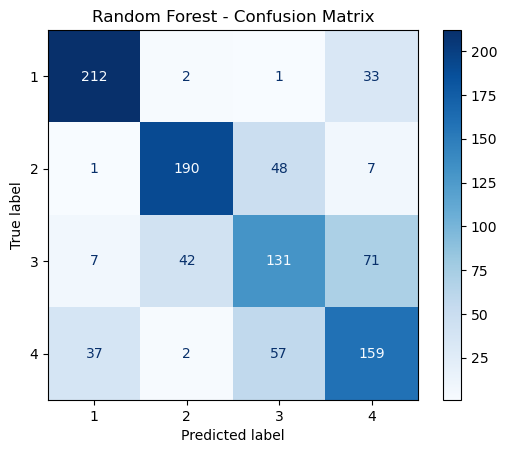

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_valid, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [9]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred))

              precision    recall  f1-score   support

           1       0.82      0.85      0.84       248
           2       0.81      0.77      0.79       246
           3       0.55      0.52      0.54       251
           4       0.59      0.62      0.61       255

    accuracy                           0.69      1000
   macro avg       0.69      0.69      0.69      1000
weighted avg       0.69      0.69      0.69      1000



Model 1: Random Forest

Method: Direct multiclass classification
Number of trees: 100
Validation Accuracy: 69.2%

Observation:
The model performs better on classes 1 and 2
than on classes 3 and 4.
Classes 3 and 4 are often confused with each other.

In [10]:
#utiliser OVA model dans le mémoire
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the OVA model
ova_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)

# Train the model
ova_model.fit(X_train, y_train)

# Predict the validation set
y_pred_ova = ova_model.predict(X_valid)

# Calculate accuracy
accuracy_ova = accuracy_score(y_valid, y_pred_ova)

print("OVA Random Forest Accuracy:", accuracy_ova)

OVA Random Forest Accuracy: 0.695


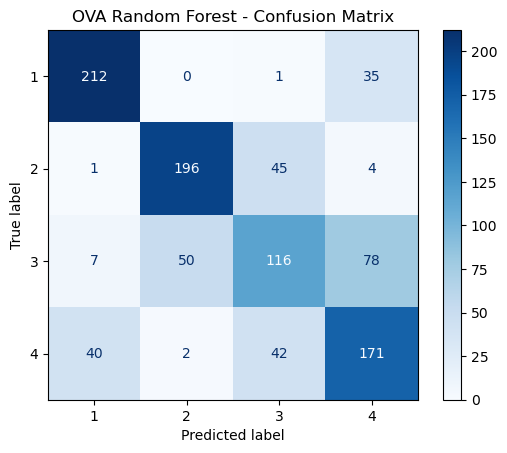

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_ova = confusion_matrix(y_valid, y_pred_ova)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ova,
    display_labels=[1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("OVA Random Forest - Confusion Matrix")
plt.show()

In [12]:
from sklearn.metrics import classification_report
print(classification_report(y_valid, y_pred_ova))

              precision    recall  f1-score   support

           1       0.82      0.85      0.83       248
           2       0.79      0.80      0.79       246
           3       0.57      0.46      0.51       251
           4       0.59      0.67      0.63       255

    accuracy                           0.69      1000
   macro avg       0.69      0.70      0.69      1000
weighted avg       0.69      0.69      0.69      1000



In [13]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Create the Boosting model
boost_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
boost_model.fit(X_train, y_train)

# Predict the validation set
y_pred_boost = boost_model.predict(X_valid)

# Calculate accuracy
accuracy_boost = accuracy_score(y_valid, y_pred_boost)

print("Boosting Accuracy:", accuracy_boost)

Boosting Accuracy: 0.733


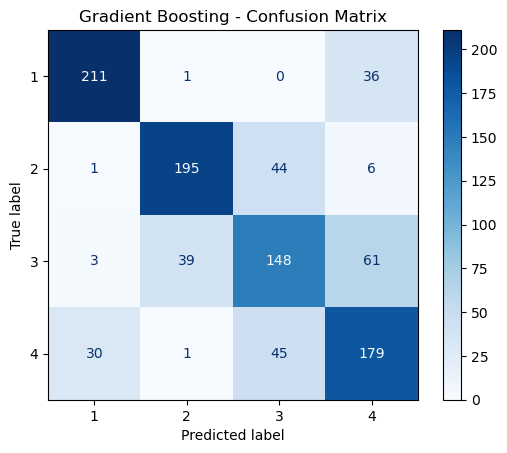

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_boost = confusion_matrix(y_valid, y_pred_boost)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_boost,
    display_labels=[1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_valid, y_pred_boost))

              precision    recall  f1-score   support

           1       0.86      0.85      0.86       248
           2       0.83      0.79      0.81       246
           3       0.62      0.59      0.61       251
           4       0.63      0.70      0.67       255

    accuracy                           0.73      1000
   macro avg       0.74      0.73      0.73      1000
weighted avg       0.74      0.73      0.73      1000



In [16]:
# Compare the models

results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'OVA + Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy,
        accuracy_ova,
        accuracy_boost
    ]
})

print(results)

                 Model  Accuracy
0        Random Forest     0.692
1  OVA + Random Forest     0.695
2    Gradient Boosting     0.733



## Model Comparison – Baseline Models

Three classification approaches were evaluated using the same training and validation sets.

### 1. Methods

- **Random Forest:** Direct multiclass classification using an ensemble of decision trees.
- **One-vs-All (OVA):** Four binary classifiers were trained, each separating one class from the remaining classes, using Random Forest as the base classifier.
- **Gradient Boosting:** A boosting model was trained directly for multiclass classification.

### 2. Validation Results

| Model | Accuracy |
| Random Forest | 69.2% |
| OVA + Random Forest | 69.5% |
| Gradient Boosting | 73.3% |

### 3. Analysis

Gradient Boosting achieved the highest validation accuracy (73.3%), outperforming Random Forest (69.2%) and OVA + Random Forest (69.5%).

The classification report also shows that Gradient Boosting achieved better F1-scores for all four classes than the two Random Forest approaches.

However, class 3 remains more difficult to predict than the other classes.

### 4. Conclusion

Among the three baseline models, Gradient Boosting obtained the best overall validation performance. Therefore, it will be selected for further hyperparameter optimization.


In [17]:
# Hyperparameter Optimization
GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

GradientBoostingClassifier(random_state=42)

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3]
}

# Create Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit Grid Search on the training set
grid_search.fit(X_train, y_train)

# Display the best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best CV Accuracy: 0.738


In [19]:
# Get the best model
best_gb_model = grid_search.best_estimator_

# Predict the validation set
y_pred_best = best_gb_model.predict(X_valid)

# Calculate validation accuracy
best_accuracy = accuracy_score(y_valid, y_pred_best)

print("Optimized Gradient Boosting Accuracy:", best_accuracy)

Optimized Gradient Boosting Accuracy: 0.761


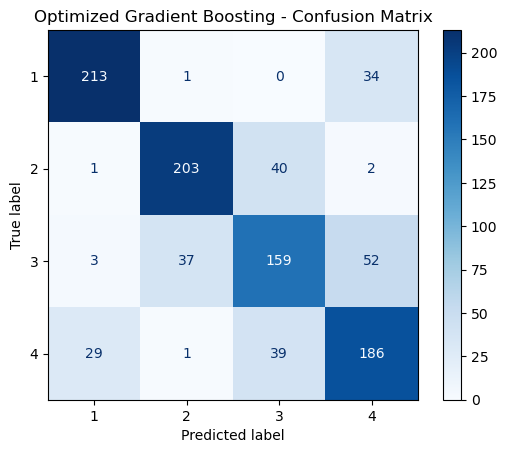

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_best = confusion_matrix(y_valid, y_pred_best)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=[1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("Optimized Gradient Boosting - Confusion Matrix")
plt.show()

In [21]:
from sklearn.metrics import classification_report
print(classification_report(y_valid, y_pred_best))

              precision    recall  f1-score   support

           1       0.87      0.86      0.86       248
           2       0.84      0.83      0.83       246
           3       0.67      0.63      0.65       251
           4       0.68      0.73      0.70       255

    accuracy                           0.76      1000
   macro avg       0.76      0.76      0.76      1000
weighted avg       0.76      0.76      0.76      1000




## Optimized Gradient Boosting – Evaluation

### 1. Confusion Matrix

The optimized Gradient Boosting model correctly classified 761 out of 1,000 validation observations.

### 2. Classification Performance

The model achieved:

- Accuracy: 76.1%
- Macro-average Precision: 0.76
- Macro-average Recall: 0.76
- Macro-average F1-score: 0.76

Class 1 achieved the highest F1-score (0.86), while class 3 remained the most difficult class to predict (0.65).

### 3. Comparison with the Baseline Model

Validation accuracy increased from 73.3% to 76.1%, representing an improvement of 2.8 percentage points.

F1-scores also improved for classes 2, 3 and 4, while class 1 remained unchanged.

### 4. Conclusion

Hyperparameter optimization improved the overall classification performance of Gradient Boosting. The optimized model achieved the best validation accuracy among the models evaluated so far.



In [22]:
print(train.columns.tolist())
print(train.shape)

['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase', 'y']
(5000, 17)


In [23]:
print("Test columns:")
print(test.columns.tolist())
print("Test shape:")
print(test.shape)
display(test.head())

Test columns:
['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase', 'id']
Test shape:
(55000, 17)


,numsessions,numdays,numpurchases,totpurchases,totplaytime,totscore,numlives,numelements,difflevel,skill1,skill2,country,opsys,acquis,trendsession,trendpurchase,id
0,9,6,2,14.776380,164.841536,92.923682,27,17,1,0.384018,0.775148,2,1,0,1.907885,-0.639091,1
1,6,5,2,5.683107,295.196816,97.009272,30,19,1,0.515540,0.570245,6,1,0,1.038746,-0.107908,2
2,8,7,2,6.304013,423.960085,103.876538,29,18,2,0.452954,0.481273,4,1,0,1.790213,0.946940,3
3,5,7,4,3.784258,253.170995,103.833506,31,21,1,0.500199,0.763884,6,1,0,1.765677,2.580624,4
4,15,7,5,6.173808,464.914152,109.848563,45,29,2,0.750821,0.313256,3,0,0,4.078027,3.541112,5


In [24]:
# Separate features and target
X = train.drop(columns=['y'])
y = train['y']

# Remove id from test features
X_test = test.drop(columns=['id'])

# Check feature columns
print("Training features:", X.columns.tolist())
print("Test features:", X_test.columns.tolist())

# Check whether the columns match
print("Same columns:", X.columns.tolist() == X_test.columns.tolist())

print("X shape:", X.shape)
print("X_test shape:", X_test.shape)

Training features: ['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase']
Test features: ['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase']
Same columns: True
X shape: (5000, 16)
X_test shape: (55000, 16)


In [26]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the final model
final_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train on all 5,000 observations
final_model.fit(X, y)

print("Final model training completed.")

Final model training completed.


In [27]:
# Predict the test set
y_test_pred = final_model.predict(X_test)

# Check predictions
print("Prediction shape:", y_test_pred.shape)
print("Predicted classes:")
print(pd.Series(y_test_pred).value_counts().sort_index())

Prediction shape: (55000,)
Predicted classes:
1    13252
2    13566
3    13462
4    14720
Name: count, dtype: int64


In [28]:
# Create submission file
submission = pd.DataFrame({
    'id': test['id'],
    'y': y_test_pred
})

# Save as CSV
submission.to_csv(
    '/Users/tangjuanzhe/Desktop/submission.csv',
    index=False
)

print("Submission file created successfully!")

# Check the submission file
print(submission.shape)
display(submission.head())

Submission file created successfully!
(55000, 2)


,id,y
0,1,2
1,2,4
2,3,3
3,4,4
4,5,2


In [29]:
# Check submission structure
print("Columns:", submission.columns.tolist())
print("Number of rows:", len(submission))
print("Missing values:")
print(submission.isnull().sum())

print("Predicted classes:")
print(submission['y'].value_counts().sort_index())

Columns: ['id', 'y']
Number of rows: 55000
Missing values:
id    0
y     0
dtype: int64
Predicted classes:
y
1    13252
2    13566
3    13462
4    14720
Name: count, dtype: int64


In [30]:
#utiliser OVO
from sklearn.multiclass import OneVsOneClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the OVO model
ovo_model = OneVsOneClassifier(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)

# Train the model
ovo_model.fit(X_train, y_train)

# Predict the validation set
y_pred_ovo = ovo_model.predict(X_valid)

# Calculate accuracy
accuracy_ovo = accuracy_score(y_valid, y_pred_ovo)

print("OVO Random Forest Accuracy:", accuracy_ovo)

OVO Random Forest Accuracy: 0.686


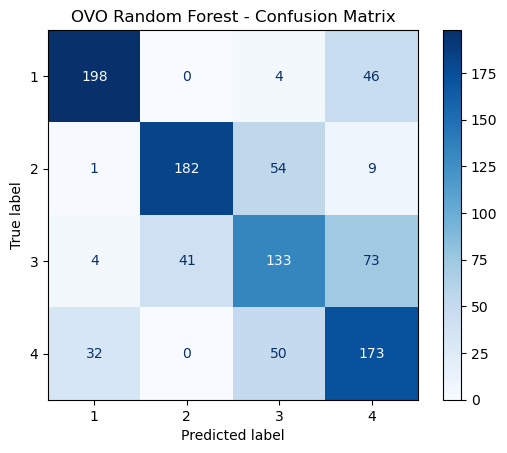

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_ovo = confusion_matrix(y_valid, y_pred_ovo)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ovo,
    display_labels=[1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("OVO Random Forest - Confusion Matrix")
plt.show()

In [32]:
from sklearn.metrics import classification_report
print(classification_report(y_valid, y_pred_ovo))

              precision    recall  f1-score   support

           1       0.84      0.80      0.82       248
           2       0.82      0.74      0.78       246
           3       0.55      0.53      0.54       251
           4       0.57      0.68      0.62       255

    accuracy                           0.69      1000
   macro avg       0.70      0.69      0.69      1000
weighted avg       0.69      0.69      0.69      1000



In [ ]:
#parce que accuarcy n'est pas meilleur,maintenant je utilise XGboost
import xgboost

print("XGBoost version:", xgboost.__version__)